# 05 · Análisis: dónde, cuándo y a quién proponer primero

**Pregunta:** ¿dónde, cuándo y a quién debe la marca proponer primero sus prendas, y con qué idea?

Este notebook solo lee los archivos limpios del notebook 03 (no pide nada a internet). Cada hipótesis se comprueba con los datos y, cuando hace falta, con una **simulación**: se barajan los datos muchas veces y se mira con qué frecuencia el azar da un resultado tan fuerte como el real. Si el azar lo da a menudo, el resultado no es una conclusión.

Los nombres de proveedores, clientes y contactos no se muestran: solo cifras. Los gráficos se guardan en `figuras/` para los slides.

> **Cómo leer este notebook.** Antes de cada celda de código hay un bloque **Cómo funciona**: qué hace la celda, por qué se hace así y qué herramientas usa. Cuando algo no se ha visto en clase, se marca como **Nuevo** y se explica con más calma. Las funciones que se llaman (`recoleccion.…`, `cleaning.…`, `analisis.…`) están en la carpeta `src/`, con su explicación en el docstring.

**Cómo funciona**

- **Qué hace:** prepara el notebook (módulos, configuración, estilo de los gráficos) y lee los archivos limpios. Vuelve a aplicar las exclusiones como segunda comprobación y filtra los contratos de cámaras y juntas.
- **Por qué así:** `dtype={"telefono": str}` lee el teléfono como texto: si no, pandas lo convierte en número y pierde el «+351». `parse_dates` convierte las columnas de fecha al leer.
- **Herramientas:** `read_csv(parse_dates=..., dtype=...)`, `isin`.
- **Nuevo (no visto en clase):** `importlib.reload`.

In [79]:
import importlib
import sys
from datetime import date
from pathlib import Path

import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))

from src import analisis, cleaning, graficos, recoleccion

# Recarga el código de src/ por si ha cambiado (cleaning primero, porque analisis lo usa)
for modulo in (cleaning, recoleccion, analisis, graficos):
    importlib.reload(modulo)

config = recoleccion.cargar_config(RAIZ / "config.yaml")
RUTA_RAW = RAIZ / config["rutas"]["raw"]
RUTA_CLEAN = RAIZ / config["rutas"]["clean"]
RUTA_INTERNO = RAIZ / config["rutas"]["interno"]
graficos.estilo_beira()
HOY = pd.Timestamp(date.today())

municipios = pd.read_csv(RUTA_CLEAN / "municipios.csv", parse_dates=["fecha_2026", "fecha_2027"])
leads = pd.read_csv(RUTA_CLEAN / "leads_organizaciones.csv", dtype={"telefono": str})  # texto: si no, el teléfono se lee como número y pierde el +
ruta_exclusiones = RUTA_INTERNO / "exclusiones.csv"
if ruta_exclusiones.exists():  # segunda comprobación, aunque el notebook 03 ya las quita
    leads, _ = cleaning.aplicar_exclusiones(leads, pd.read_csv(ruta_exclusiones))
contratos = pd.read_csv(RUTA_INTERNO / "contratos_ropa_region.csv", parse_dates=["fecha"], low_memory=False)
autarquias = contratos[contratos["tipo_comprador"].isin(["camara", "junta"])]
print(len(municipios), "municipios ·", len(leads), "organizaciones ·", len(autarquias), "contratos de autarquías")

66 municipios · 1596 organizaciones · 265 contratos de autarquías


## 1. A quién: organizaciones y contacto público (H3)

**H3:** menos de la mitad de los clientes potenciales tiene email público.

**Cómo funciona**

- **Qué hace:** calcula el % de organizaciones con email y con teléfono por segmento, el total con y sin colegios, y dibuja el gráfico.
- **Por qué así:** `lambda s: s.notna().mean() * 100` da el % de valores no vacíos (la media de verdaderos y falsos es la proporción). Se separan los colegios porque publican email casi siempre y esconden lo que pasa en el resto. Los segmentos núcleo (club, asociación, autarquía) van en terracota.
- **Herramientas:** `groupby().agg()` con nombres, `lambda`, `sort_values`, funciones de `graficos`.

,organizaciones,con_email,con_telefono
segmento,,,
escuela,809,80.2,84.8
autarquia,304,5.6,9.9
instalacion_deportiva,189,2.1,9.5
bomberos,108,17.6,25.9
asociacion,81,6.2,6.2
club,61,8.2,9.8


Con email público: 45% del total y 7% sin contar los colegios


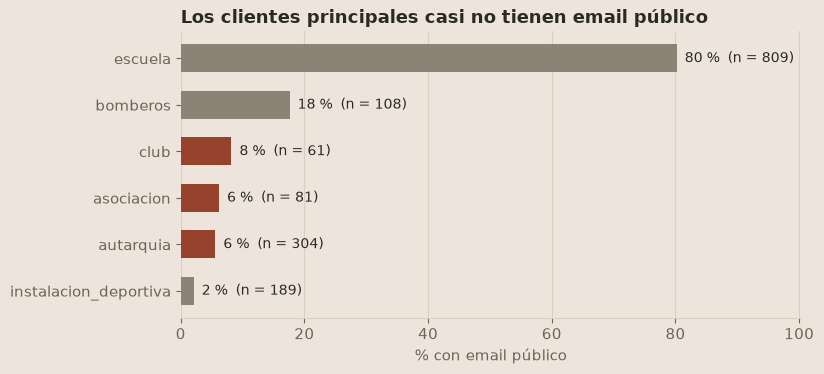

In [80]:
osm = leads[leads["origen"] == "OpenStreetMap"]
contacto = osm.groupby("segmento").agg(
    organizaciones=("nombre", "count"),
    con_email=("email", lambda s: s.notna().mean() * 100),
    con_telefono=("telefono", lambda s: s.notna().mean() * 100),
).round(1).sort_values("organizaciones", ascending=False)
display(contacto)

sin_colegios = osm[osm["segmento"] != "escuela"]
print(f"Con email público: {osm['email'].notna().mean():.0%} del total y {sin_colegios['email'].notna().mean():.0%} sin contar los colegios")

fig = graficos.barras_horizontales(
    contacto["con_email"], "Los clientes principales casi no tienen email público", "% con email público",
    destacar=["club", "asociacion", "autarquia"], formato="{:.0f} %",
    notas={s: f"(n = {n})" for s, n in contacto["organizaciones"].items()},
)
graficos.guardar(fig, "h3_email_por_segmento")

## 2. Dónde: índice de oportunidad por municipio

Cinco medidas por municipio, cada una pasada a una escala de 0 a 1 según su posición entre los 66:

- **organizaciones** por 1.000 habitantes (más es mejor);
- **gasto** de cámaras y juntas en ropa por habitante, 2020-2025 (más es mejor);
- **jóvenes** de 5 a 24 años, en % (más es mejor);
- **competencia**: gráficas y confecciones del INE por 10.000 habitantes (menos es mejor);
- **cercanía** a Oliveira do Hospital (más cerca es mejor).

Los pesos son una **decisión**, no un dato. Por eso se prueban dos conjuntos (A: todo igual; B: más peso a la cercanía) y se mira si el top 10 cambia mucho.

**Cómo funciona**

- **Qué hace:** calcula el índice de oportunidad de los 66 municipios con dos conjuntos de pesos, compara sus top 10, muestra el puesto del piloto y guarda `indice_municipios.csv`.
- **Por qué así:** cada medida se pasa a percentil con `rank(pct=True)`: de 0 a 1 según su posición entre los 66. Se usa la posición y no el valor porque Coimbra y Viseu tienen valores tan grandes que se comerían la escala. Competencia y distancia se invierten (menos es mejor). El índice es una media ponderada × 100. Los pesos son una decisión: por eso hay dos (A y B) y se mira cuánto cambia el top 10.
- **Herramientas:** `rank`, operaciones entre columnas, `sort_values`, `head`, sets e intersección (`&`).
- **Nuevo (no visto en clase):** percentiles con `rank(pct=True)` y la prueba de robustez (comparar dos conjuntos de pesos).

Municipios en el top 10 con los dos conjuntos de pesos: 5 de 10
Puesto de los municipios del piloto (pesos B): {'Arganil': 5, 'Oliveira do Hospital': 20, 'Tábua': 12, 'Carregal do Sal': 6, 'Nelas': 2, 'Seia': 44}


,municipio,distrito,indice_a,indice_b,km_a_la_base,organizaciones_por_1000_hab,gasto_autarquias_ropa
5,Góis,Coimbra,66.7,73.7,31.0,2.88,17000.00
25,Nelas,Viseu,70.2,71.7,19.0,1.77,1666.00
60,Oleiros,Castelo Branco,67.6,71.7,49.0,2.69,76467.25
38,Vila Nova de Paiva,Viseu,74.1,69.6,56.0,3.02,15532.51
0,Arganil,Coimbra,58.5,66.3,22.0,3.79,0.00
18,Carregal do Sal,Viseu,58.6,65.2,15.0,1.49,25670.00
58,Fundão,Castelo Branco,60.8,64.1,39.0,1.94,95936.45
37,Tondela,Viseu,57.7,62.8,26.0,1.89,0.00
39,Viseu,Viseu,61.1,61.6,34.0,1.15,636282.34
23,Moimenta da Beira,Viseu,70.5,61.5,72.0,1.76,158048.00


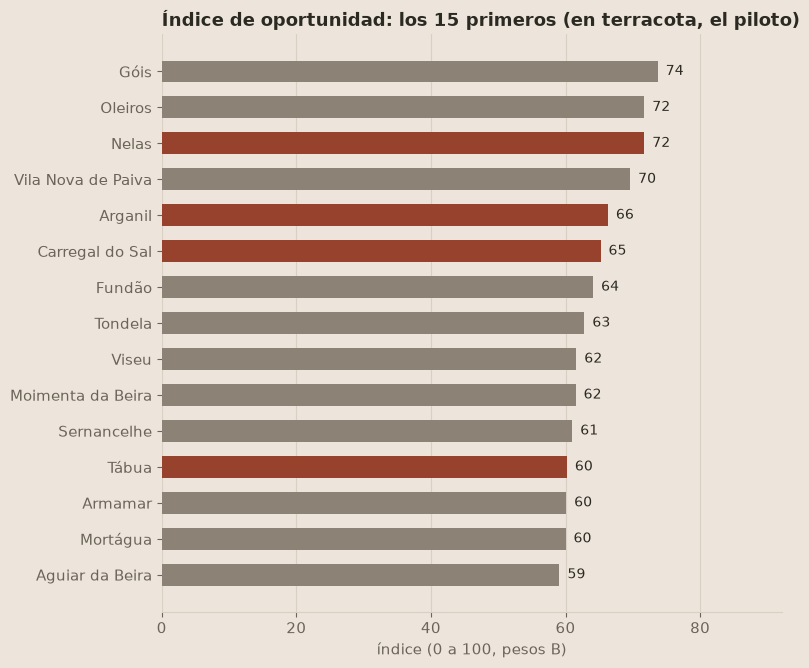

In [81]:
componentes = analisis.componentes_indice(municipios)
municipios["indice_a"] = analisis.indice_oportunidad(componentes, config["indice"]["pesos_a"])
municipios["indice_b"] = analisis.indice_oportunidad(componentes, config["indice"]["pesos_b"])

coinciden = analisis.coincidencia_top(municipios["indice_a"], municipios["indice_b"], municipios["municipio"])
print("Municipios en el top 10 con los dos conjuntos de pesos:", coinciden, "de 10")

puestos = municipios["indice_b"].rank(ascending=False, method="min").astype(int)
print("Puesto de los municipios del piloto (pesos B):", dict(zip(municipios.loc[municipios["piloto"], "municipio"], puestos[municipios["piloto"]])))

top = municipios.sort_values("indice_b", ascending=False).head(15)
display(top[["municipio", "distrito", "indice_a", "indice_b", "km_a_la_base", "organizaciones_por_1000_hab", "gasto_autarquias_ropa"]])

fig = graficos.barras_horizontales(
    top.set_index("municipio")["indice_b"], "Índice de oportunidad: los 15 primeros (en terracota, el piloto)",
    "índice (0 a 100, pesos B)", destacar=config["region"]["piloto"],
)
graficos.guardar(fig, "indice_oportunidad_top15")
municipios[["municipio", "distrito", "piloto", "indice_a", "indice_b"]].to_csv(RUTA_CLEAN / "indice_municipios.csv", index=False)

### Cercanía: lo que hay cerca de la base

Una marca pequeña vende primero cerca de casa. ¿Cuánto del mercado está a menos de 40 o 60 km de Oliveira do Hospital? Y, entre las autarquías que compran ropa varios años, ¿cuáles están cerca?

**Cómo funciona**

- **Qué hace:** calcula el % de organizaciones y de gasto a 20, 40 y 60 km, y busca las autarquías que compran en dos años o más a 60 km o menos.
- **Por qué así:** `map` lleva a cada contrato la distancia de su municipio; `groupby("comprador_nif").agg(...)` resume cada comprador (años distintos, contratos, gasto, distancia).
- **Herramientas:** `set_index`, `map`, `assign`, `groupby().agg()`, filtros con `&`.

In [82]:
km_municipio = municipios.set_index("municipio")["km_a_la_base"]
autarquias_km = autarquias.assign(km=autarquias["municipio"].map(km_municipio))
for radio in [20, 40, 60]:
    print(f"A {radio} km o menos: {(osm['km_a_la_base'] <= radio).mean():.0%} de las organizaciones y "
          f"{autarquias_km.loc[autarquias_km['km'] <= radio, 'precio'].sum() / autarquias_km['precio'].sum():.0%} del gasto de las autarquías")

# Compradores que vuelven a comprar (dos años o más) y están a 60 km o menos: la segunda frente de la marca
compradores = autarquias_km.groupby("comprador_nif").agg(
    comprador=("comprador", "first"), municipio=("municipio", "first"), anos=("ano", "nunique"), contratos=("idcontrato", "count"),
    gasto=("precio", "sum"), km=("km", "first"),
)
recurrentes_cerca = compradores[(compradores["anos"] >= 2) & (compradores["km"] <= 60)].sort_values("km")
print(f"Autarquías que compran en dos años o más a 60 km o menos: {len(recurrentes_cerca)}, "
      f"con {recurrentes_cerca['gasto'].sum():,.0f} € en 2020-2025")
display(recurrentes_cerca[["comprador", "municipio", "anos", "contratos", "gasto", "km"]].round(0).reset_index(drop=True))

A 20 km o menos: 8% de las organizaciones y 1% del gasto de las autarquías
A 40 km o menos: 35% de las organizaciones y 18% del gasto de las autarquías
A 60 km o menos: 63% de las organizaciones y 49% del gasto de las autarquías
Autarquías que compran en dos años o más a 60 km o menos: 11, con 2,232,584 € en 2020-2025


,comprador,municipio,anos,contratos,gasto,km
0,Município de Mortágua,Mortágua,2,2,41010.0,32.0
1,Município de Viseu,Viseu,6,27,616010.0,34.0
2,Serviços Municipalizados de Água e Saneamento ...,Viseu,2,3,20272.0,34.0
3,Município do Fundão,Fundão,3,3,95936.0,39.0
4,Município da Lousã,Lousã,4,5,35144.0,42.0
5,Município de Belmonte,Belmonte,4,7,169449.0,43.0
6,Município de Oleiros,Oleiros,4,4,76467.0,49.0
7,Município de Miranda do Corvo,Miranda do Corvo,3,4,43112.0,50.0
8,Serviços Municipalizados de Transportes Urbano...,Coimbra,4,17,256891.0,51.0
9,Município de Coimbra,Coimbra,6,27,418343.0,51.0


### Competencia

Tres miradas: el INE (empresas de confección y de impresión por municipio, 2022), los proveedores de las autarquías en el BASE (por lo que dice su nombre) y OpenStreetMap.

**Cómo funciona**

- **Qué hace:** mide la competencia de tres formas: empresas por municipio (INE), % del gasto según el tipo de proveedor (BASE) y lo que registra OpenStreetMap.
- **Por qué así:** ninguna fuente basta sola. OpenStreetMap no tiene ninguna bordadora ni imprenta, así que no sirve para medir la competencia.
- **Herramientas:** `assign`, `loc` con filtro, `groupby().sum()`, `sum(min_count=1)`.

In [83]:
competencia = municipios.assign(
    competencia_por_10000_hab=(municipios["ine_vestuario_2022"] + municipios["ine_impresion_2022"]) / municipios["poblacion"] * 10000
)
print("Región: confección", int(competencia["ine_vestuario_2022"].sum()), "empresas; impresión", int(competencia["ine_impresion_2022"].sum()),
      "; municipios sin ninguna gráfica:", int((competencia["ine_impresion_2022"] == 0).sum()))
display(competencia.loc[competencia["piloto"], ["municipio", "ine_vestuario_2022", "ine_impresion_2022", "competencia_por_10000_hab"]].round(1))

# Quién gana los contratos de las autarquías, según el nombre del proveedor (solo porcentajes)
tipo = autarquias.groupby("tipo_proveedor")["precio"].sum().sort_values(ascending=False)
display((tipo / tipo.sum() * 100).round(1).rename("% del gasto"))

print("OpenStreetMap: bordadoras", int(municipios["competencia_bordado"].sum()), "· imprentas", int(municipios["competencia_imprenta"].sum()),
      "· negocios encontrados por el nombre (gráfica, estampagem...):", int(municipios["graficas_total"].sum(min_count=1) or 0))

Región: confección 361 empresas; impresión 178 ; municipios sin ninguna gráfica: 19


,municipio,ine_vestuario_2022,ine_impresion_2022,competencia_por_10000_hab
0,Arganil,3,2,4.4
10,Oliveira do Hospital,15,4,9.6
15,Tábua,8,3,9.5
18,Carregal do Sal,2,3,5.3
25,Nelas,3,1,2.9
52,Seia,12,5,7.8


tipo_proveedor
otro               81.3
publicidad          5.3
estampagem          3.9
grafica             3.6
personalizacion     2.8
fardamento          2.6
bordados            0.4
Name: % del gasto, dtype: float64

OpenStreetMap: bordadoras 0 · imprentas 0 · negocios encontrados por el nombre (gráfica, estampagem...): 12


### Mercado de la oferta Trabajo

Empresas que visten a su personal: alojamiento, restauración, salud y apoyo social (INE 2022, solo sociedades). Se compara con lo que registra OpenStreetMap.

**Cómo funciona**

- **Qué hace:** cuenta por municipio las sociedades de alojamiento, restauración, salud y apoyo social (INE) y las compara con OpenStreetMap.
- **Por qué así:** son las empresas que visten a su personal (oferta Trabajo). Se cuentan solo sociedades: un empresario individual casi nunca tiene personal al que vestir.
- **Herramientas:** dict comprehension con dos `for`, `glob`, `pd.DataFrame`, `sum(axis=1)`, `loc`.

In [84]:
divisiones_trabajo = {"55": "alojamiento", "56": "restauracion", "86": "salud", "88": "apoyo_social"}
carpeta_div = RUTA_RAW / f"ine_{config['ine']['indicador_empresas_division']}"
trabajo = pd.DataFrame({
    nombre: analisis.empresas_division(recoleccion.leer_json(ruta), municipios["municipio"].tolist())
    for codigo, nombre in divisiones_trabajo.items()
    for ruta in carpeta_div.glob(f"*_{codigo}.json")
})
trabajo["total"] = trabajo.sum(axis=1)
print("Sociedades de la oferta Trabajo en la región:", trabajo.sum().astype(int).to_dict())
osm_restauracion = municipios.set_index("municipio")[["trabajo_restaurante", "trabajo_cafe", "trabajo_hotel"]].sum(axis=1)
print(f"OpenStreetMap registra {int(osm_restauracion.sum())} restaurantes, cafés y hoteles con nombre; "
      f"el INE cuenta {int(trabajo['alojamiento'].sum() + trabajo['restauracion'].sum())} sociedades de alojamiento y restauración")
display(trabajo.loc[config["region"]["piloto"]].astype(int))

Sociedades de la oferta Trabajo en la región: {'alojamiento': 1265, 'restauracion': 2699, 'salud': 2455, 'apoyo_social': 70, 'total': 6489}
OpenStreetMap registra 2872 restaurantes, cafés y hoteles con nombre; el INE cuenta 3964 sociedades de alojamiento y restauración


,alojamiento,restauracion,salud,apoyo_social,total
municipio,,,,,
Oliveira do Hospital,37,47,26,1,111
Arganil,26,29,17,0,72
Carregal do Sal,4,11,13,1,29
Nelas,19,24,16,1,60
Seia,40,55,38,0,133
Tábua,20,24,11,0,55


## 3. Cuándo compran las autarquías (H1)

**H1:** las compras públicas de ropa y merchandising se concentran en ciertos meses.

**Cómo funciona**

- **Qué hace:** construye la tabla de gasto por año y mes (mapa de calor), busca el mes de más gasto de cada año y hace dos pruebas por simulación.
- **Por qué así:** `pivot_table` pone los años en filas y los meses en columnas. Prueba 1 (`prueba_mismo_mes`): se barajan los meses entre contratos 2.000 veces y se cuenta cuántas veces el azar da tantas coincidencias del mes fuerte como las reales; sale un 19 %, así que puede ser azar y la H1 no se cumple. Prueba 2 (`prueba_meses_uniformes`): mide con chi-cuadrado cuánto se aleja el reparto de contratos por mes de un reparto igual y lo compara con repartos al azar; p = 0,004, así que los contratos sí se reparten de forma desigual entre meses.
- **Herramientas:** `pivot_table`, `reindex`, f-strings.
- **Nuevo (no visto en clase):** las pruebas por simulación (permutación) con `numpy.random.default_rng` y el chi-cuadrado. La idea: si barajando los datos sale a menudo un resultado igual de fuerte, el resultado real no demuestra nada.

Mes de más gasto cada año: {2020: 3, 2021: 2, 2022: 8, 2023: 7, 2024: 7, 2025: 7}


El mismo mes es el primero en 3 de 6 años; el azar lo da en el 19% de las simulaciones
Contratos por mes: chi2 = 30.0, p = 0.004 (si p < 0,05, los contratos no se reparten igual entre meses)


mes,1,2,3,4,5,6,7,8,9,10,11,12
contratos,6.0,23.0,29.0,14.0,20.0,21.0,28.0,36.0,22.0,20.0,18.0,28.0
gasto,61961.0,389824.0,638822.0,294360.0,318656.0,489714.0,724758.0,571299.0,350004.0,343767.0,216598.0,516861.0


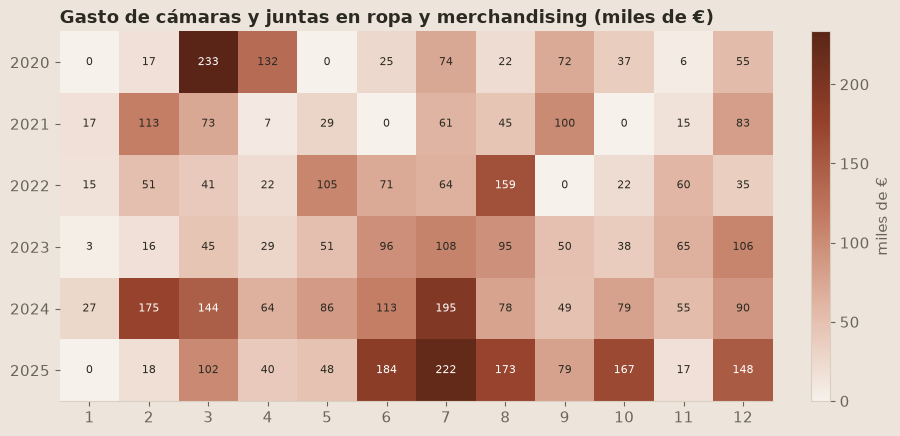

In [85]:
tabla = autarquias.pivot_table(index="ano", columns="mes", values="precio", aggfunc="sum", fill_value=0) / 1000
tabla = tabla.reindex(columns=range(1, 13), fill_value=0)
fig = graficos.mapa_calor(tabla, "Gasto de cámaras y juntas en ropa y merchandising (miles de €)", "miles de €")
graficos.guardar(fig, "h1_gasto_mes_ano")

print("Mes de más gasto cada año:", analisis.mes_con_mas_gasto(autarquias).to_dict())
veces, anos, p = analisis.prueba_mismo_mes(autarquias)
print(f"El mismo mes es el primero en {veces} de {anos} años; el azar lo da en el {p:.0%} de las simulaciones")
chi2, p_meses = analisis.prueba_meses_uniformes(autarquias["mes"])
print(f"Contratos por mes: chi2 = {chi2}, p = {p_meses:.3f} (si p < 0,05, los contratos no se reparten igual entre meses)")
display(autarquias.groupby("mes")["precio"].agg(contratos="count", gasto="sum").round(0).T)

## 4. Cuándo hay fiestas (H4) y cuándo se busca en internet

**H4:** los festivos municipales se concentran en pocos meses. Se añaden las fiestas de verano de Oliveira do Hospital (recogidas en fuentes públicas, archivo interno) y Google Trends (5 años, Portugal). En Trends se usan los tres términos con más búsquedas: con pocas búsquedas, el índice mensual es ruido.

**Cómo funciona**

- **Qué hace:** cuenta los festivos municipales por mes (27 de 66 en junio o septiembre) y las fiestas de aldea de Oliveira do Hospital (22 de 30 de junio a agosto).
- **Por qué así:** las fiestas de aldea vienen de un Excel interno de la marca, recogidas a mano en fuentes públicas; solo se usan las que tienen una fuente con enlace (`startswith("http")`).
- **Herramientas:** `dt.month`, `value_counts`, `read_excel(sheet_name=...)`, `between`.

Junio y septiembre: 27 de 66
Fiestas de Oliveira do Hospital entre junio y agosto: 22 de 30


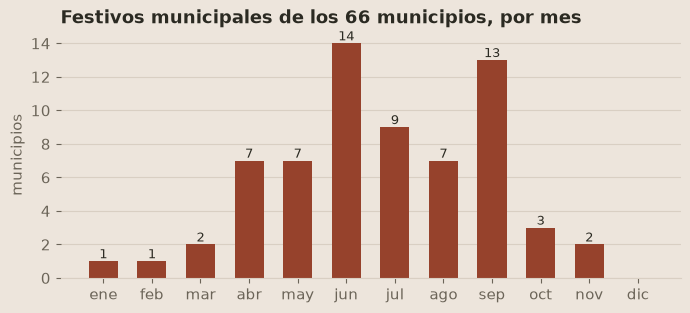

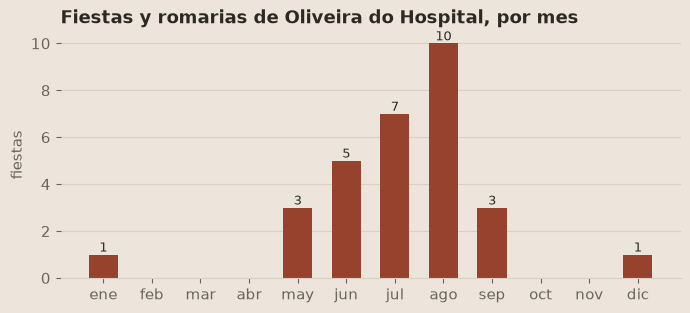

In [86]:
festivos_mes = municipios["fecha_2026"].dt.month.value_counts()
fig = graficos.barras_por_mes(festivos_mes, "Festivos municipales de los 66 municipios, por mes", "municipios")
graficos.guardar(fig, "h4_festivos_por_mes")
print("Junio y septiembre:", int(festivos_mes.get(6, 0) + festivos_mes.get(9, 0)), "de", len(municipios))

ruta_datos_beira = RUTA_INTERNO / "datos_beira_preenchido.xlsx"
if ruta_datos_beira.exists():
    festas = pd.read_excel(ruta_datos_beira, sheet_name="festas_piloto")
    festas_odh = festas[festas["fuente"].astype(str).str.startswith("http")]
    fig = graficos.barras_por_mes(festas_odh["mes"].value_counts(), "Fiestas y romarias de Oliveira do Hospital, por mes", "fiestas")
    graficos.guardar(fig, "festas_oliveira_hospital")
    print("Fiestas de Oliveira do Hospital entre junio y agosto:", festas_odh["mes"].between(6, 8).sum(), "de", len(festas_odh))

### ¿Compran las autarquías antes de su festivo?

Si las cámaras compraran ropa para sus fiestas, muchos contratos se firmarían en los dos meses anteriores al festivo de su municipio. Se cuentan los días entre cada contrato y el siguiente festivo de su municipio (los festivos móviles se recalculan para cada año) y se compara con el azar, barajando los festivos entre municipios. Ojo: la fecha del contrato es posterior a la decisión de compra, y las compras de menos de 5.000 € no están en el BASE.

**Cómo funciona**

- **Qué hace:** calcula los días entre cada contrato y el siguiente festivo de su municipio, y comprueba si en los 60 días anteriores se firman más contratos que al azar.
- **Por qué así:** `tabla_festivos` calcula el festivo de cada municipio en cada año: los fijos, el mismo día; los ligados a la Pascua, a la misma distancia de la Pascua; los de tipo «tercer lunes de julio», en el mismo lugar del mes (la regla se elige comprobando cuál da la fecha de 2027 que publica la página). La prueba baraja los festivos entre municipios 2.000 veces: real 15,8 %, azar 17,6 %, p = 0,71. Las cámaras no compran para su fiesta.
- **Herramientas:** funciones, `pd.Timestamp`, `numpy` (calcula con todas las filas a la vez).
- **Nuevo (no visto en clase):** `dateutil.easter` y el cálculo con arrays de `numpy` (vectorización), mucho más rápido que un bucle fila a fila.

Contratos firmados en los 60 días antes del festivo de su municipio: 15.8 % (al azar: 17.6 %; p = 0.71)


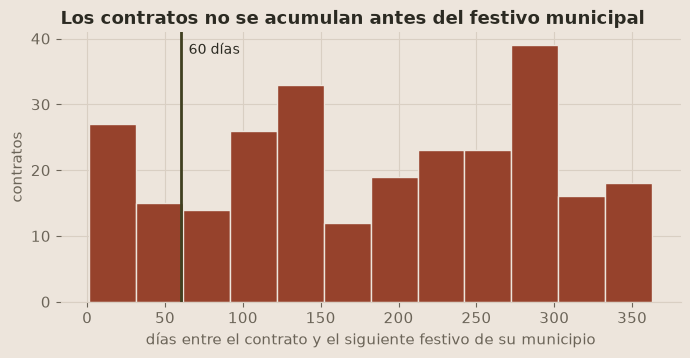

In [87]:
festivos = municipios.set_index("municipio")[["fecha_2026", "fecha_2027", "tipo_fecha"]]
dias_antes = config["analisis"]["dias_antes_festivo"]
dias_festivo = analisis.dias_hasta_festivo(autarquias, festivos)
real, azar, p = analisis.prueba_antes_del_festivo(autarquias, festivos, dias_antes, n=config["analisis"]["simulaciones"])
print(f"Contratos firmados en los {dias_antes} días antes del festivo de su municipio: {real} % (al azar: {azar} %; p = {p:.2f})")

fig = graficos.histograma(dias_festivo, "Los contratos no se acumulan antes del festivo municipal",
                          "días entre el contrato y el siguiente festivo de su municipio",
                          linea=dias_antes, texto_linea=f"{dias_antes} días", intervalos=12)
graficos.guardar(fig, "dias_hasta_festivo")

**Cómo funciona**

- **Qué hace:** lee la exportación de Google Trends, quita el último mes (incompleto), calcula el interés medio de cada mes y lo pasa a una escala en la que 100 es la media del año.
- **Por qué así:** Google Trends es un índice relativo (0 a 100), no un número de búsquedas; dividir por la media permite comparar términos entre sí. Se usan los tres términos con más búsquedas porque, con pocas, el índice mensual es ruido.
- **Herramientas:** `max(..., key=...)`, `read_csv(parse_dates=...)`, `groupby().mean()`, dividir un DataFrame por una Series.

mes,1,2,3,4,5,6,7,8,9,10,11,12
equipamentos de futebol,61.0,65.0,78.0,98.0,110.0,131.0,122.0,106.0,122.0,122.0,90.0,94.0
camisolas personalizadas,91.0,91.0,88.0,85.0,101.0,88.0,65.0,68.0,72.0,111.0,166.0,173.0
fardas,106.0,111.0,99.0,90.0,94.0,86.0,98.0,88.0,127.0,116.0,101.0,85.0


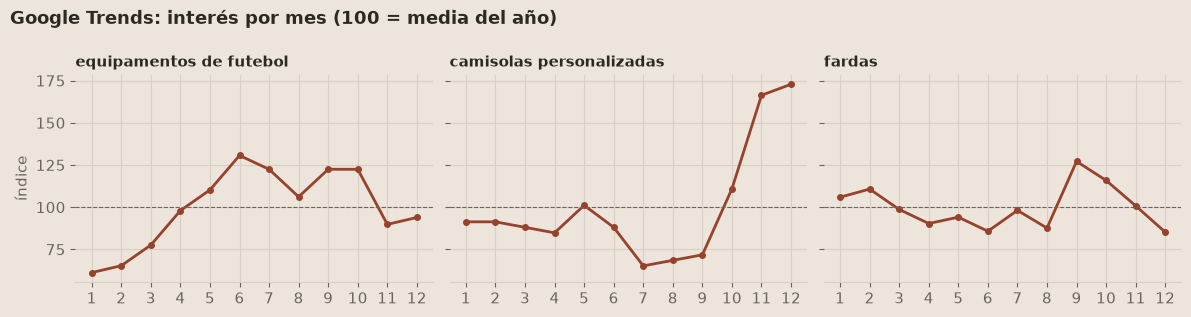

In [88]:
archivo = max((RUTA_RAW / "google_trends").glob("time_series_*.csv"), key=lambda ruta: ruta.stat().st_size)
trends = pd.read_csv(archivo, parse_dates=["Time"])
trends = trends[trends["Time"] < trends["Time"].max()]  # el último mes está incompleto
trends["mes"] = trends["Time"].dt.month
terminos = ["equipamentos de futebol", "camisolas personalizadas", "fardas"]
indice_mes = trends.groupby("mes")[terminos].mean()
indice_mes = indice_mes / indice_mes.mean() * 100  # 100 = la media del año
fig = graficos.pequenos_multiples(indice_mes, terminos, "Google Trends: interés por mes (100 = media del año)", "índice")
graficos.guardar(fig, "google_trends_meses")
display(indice_mes.round(0).T)

### Calendario comercial

Todo lo anterior, mes a mes. Cada panel tiene su escala porque mide cosas distintas (contratos, festivos, fiestas e interés en internet).

**Cómo funciona**

- **Qué hace:** junta en un gráfico, mes a mes, los contratos, los festivos, las fiestas de aldea y las búsquedas.
- **Por qué así:** cada panel tiene su propia escala porque mide cosas distintas: paneles separados en vez de un gráfico con dos ejes, que confunde.
- **Herramientas:** diccionarios, `value_counts`, la función `graficos.calendario` (matplotlib con `subplots`).

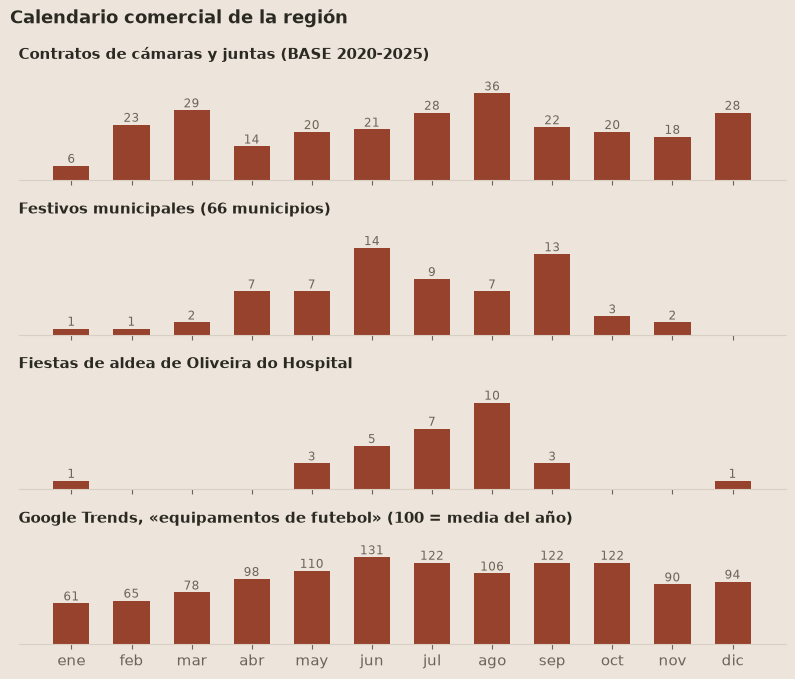

In [89]:
paneles = {
    "Contratos de cámaras y juntas (BASE 2020-2025)": autarquias["mes"].value_counts(),
    "Festivos municipales (66 municipios)": festivos_mes,
}
if ruta_datos_beira.exists():
    paneles["Fiestas de aldea de Oliveira do Hospital"] = festas_odh["mes"].value_counts()
paneles["Google Trends, «equipamentos de futebol» (100 = media del año)"] = indice_mes["equipamentos de futebol"]
fig = graficos.calendario(paneles, "Calendario comercial de la región")
graficos.guardar(fig, "calendario_comercial")

## 5. Qué compran y cómo compran

**Cómo funciona**

- **Qué hace:** dibuja el gasto por producto, con las prendas de equipo destacadas, y muestra el % de contratos por tipo de procedimiento.
- **Por qué así:** las prendas de equipo son las más parecidas a lo que hace la beira; destacarlas muestra cuánto pesan en el total.
- **Herramientas:** `groupby().agg()`, dict comprehension para las notas, `value_counts(normalize=True)`.

tipoprocedimento
Consulta Prévia               46.0
Ajuste Direto Regime Geral    42.3
Concurso público              11.7
Name: proportion, dtype: float64

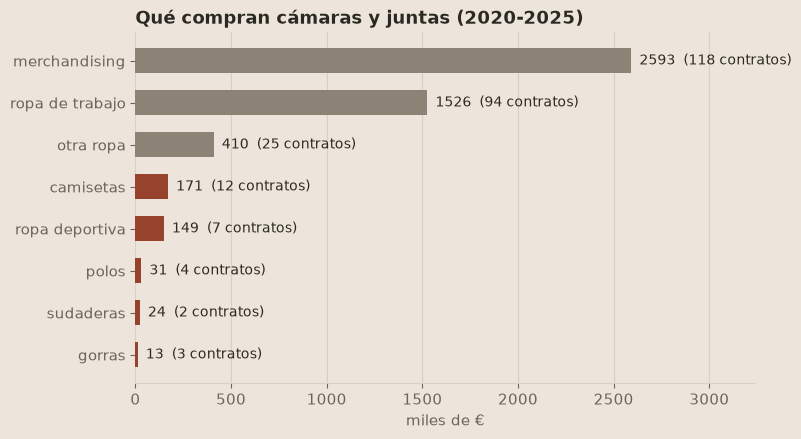

In [90]:
productos = autarquias.groupby("producto")["precio"].agg(contratos="count", gasto="sum").sort_values("gasto", ascending=False)
fig = graficos.barras_horizontales(
    productos["gasto"] / 1000, "Qué compran cámaras y juntas (2020-2025)", "miles de €",
    destacar=["camisetas", "ropa deportiva", "sudaderas", "polos", "gorras"],
    notas={p: f"({n} contratos)" for p, n in productos["contratos"].items()},
)
graficos.guardar(fig, "productos")
display((autarquias["tipoprocedimento"].value_counts(normalize=True) * 100).round(1))

**Cómo funciona**

- **Qué hace:** calcula el plazo de entrega que dan las autarquías, cuántas empresas se presentan, el % de contratos ganados por pymes y el resumen de los concursos anunciados.
- **Por qué así:** los suministros continuos duran un año y no son un plazo de entrega: se separan con `str.contains`. `clip(upper=180)` junta en la última barra los plazos de 180 días o más. El número de empresas sale de contar las líneas del texto de `concorrentes`; el dato de pyme solo existe desde 2024.
- **Herramientas:** `pd.to_numeric`, `~` (negación), `clip`, `apply(lambda)`, `split`, `query`, `str.match`.

Plazo de ejecución (sin suministros continuos): mediana 44 días; 18% dan 14 días o menos


,contratos,mediana
tipoprocedimento,,
Ajuste Direto Regime Geral,14,1.0
Concurso público,23,9.0
Consulta Prévia,97,2.0


% de contratos ganados por una PME: {2024: 67.0, 2025: 78.0}
Concursos públicos anunciados en la región (2020-2025): 110, 14 de cámaras; días para presentar propuesta: mediana 25


ano
2020    16
2021    23
2022    14
2023    27
2024    11
2025    19
Name: concursos anunciados, dtype: int64

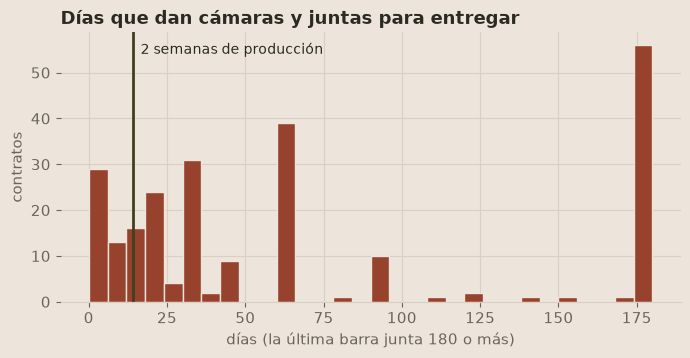

In [91]:
# Plazo de entrega frente a las 2 semanas de producción (los suministros continuos duran un año: se separan)
plazo = pd.to_numeric(autarquias["prazoExecucao"], errors="coerce")
continuo = autarquias["objectoContrato"].astype(str).str.lower().str.contains("contínuo|continuo")
plazo_puntual = plazo[~continuo]
print(f"Plazo de ejecución (sin suministros continuos): mediana {plazo_puntual.median():.0f} días; "
      f"{(plazo_puntual <= 14).mean():.0%} dan 14 días o menos")
fig = graficos.histograma(plazo_puntual.clip(upper=180), "Días que dan cámaras y juntas para entregar",
                          "días (la última barra junta 180 o más)", linea=14, texto_linea="2 semanas de producción")
graficos.guardar(fig, "plazos_entrega")

# Cuántas empresas se presentan (el dato solo existe en parte de los contratos)
empresas = autarquias["concorrentes"].fillna("").astype(str).apply(
    lambda texto: len([linea for linea in texto.split("\n") if linea.strip() and linea.strip() != "nan"])
)
display(autarquias.assign(empresas=empresas).query("empresas > 0").groupby("tipoprocedimento")["empresas"].agg(contratos="count", mediana="median"))

# PME: el dato solo existe desde 2024
pme = autarquias["adjudicatarioPMEs"].fillna("").astype(str).str.match(r"^\d{9}")
print("% de contratos ganados por una PME:", (autarquias.assign(pme=pme).groupby("ano")["pme"].mean() * 100).round(0).reindex([2024, 2025]).to_dict())

ruta_anuncios = RUTA_INTERNO / "anuncios_ropa_region.csv"
if ruta_anuncios.exists():
    anuncios = pd.read_csv(ruta_anuncios)
    print(f"Concursos públicos anunciados en la región (2020-2025): {len(anuncios)}, "
          f"{(anuncios['tipo_comprador'] == 'camara').sum()} de cámaras; días para presentar propuesta: mediana {anuncios['dias_para_propuestas'].median():.0f}")
    display(anuncios.groupby("ano").size().rename("concursos anunciados"))

## 6. Proveedores (H2 y H5)

**H2:** pocos proveedores ganan la mayor parte de los contratos. **H5:** las entidades públicas repiten proveedor de un año a otro.

**Cómo funciona**

- **Qué hace:** dibuja la curva de concentración de proveedores (H2) y hace la prueba de repetición de proveedor (H5).
- **Por qué así:** `cuota_acumulada` ordena los proveedores de mayor a menor y acumula su parte del gasto (`cumsum`): los 10 mayores llegan al 32 %, así que la H2 no se cumple. Para la H5 se cuentan las autarquías que repiten proveedor en años distintos (21 de 32) y se compara con 500 simulaciones en las que se barajan los proveedores entre contratos: al azar saldrían 6. La H5 se cumple.
- **Herramientas:** `cumsum`, `iloc`, f-strings con `:.1%`.
- **Nuevo (no visto en clase):** la prueba por permutación (barajar los proveedores).

Proveedores: 150; los 3 mayores se llevan el 14.9% y los 10 mayores el 32.1%
H5: 32 autarquías compran en dos años o más y 21 repiten proveedor; barajando los proveedores saldrían 5.9 de media (p = 0.00)


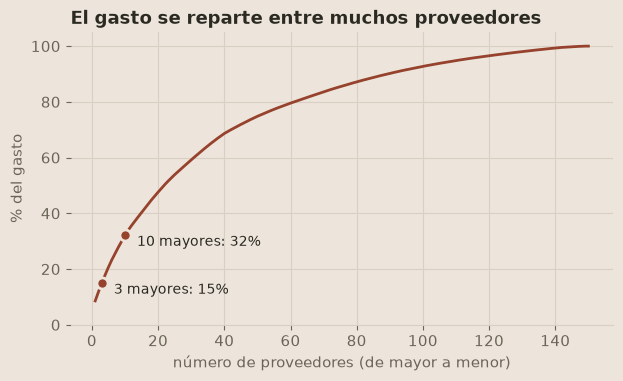

In [92]:
cuota = analisis.cuota_acumulada(autarquias)
print(f"Proveedores: {len(cuota)}; los 3 mayores se llevan el {cuota.iloc[2]:.1%} y los 10 mayores el {cuota.iloc[9]:.1%}")
fig = graficos.curva_concentracion(cuota, "El gasto se reparte entre muchos proveedores")
graficos.guardar(fig, "h2_concentracion")

recurrentes, repiten = analisis.compradores_que_repiten(autarquias)
real, azar, p = analisis.prueba_repeticion(autarquias)
print(f"H5: {recurrentes} autarquías compran en dos años o más y {repiten} repiten proveedor; "
      f"barajando los proveedores saldrían {azar} de media (p = {p:.2f})")

## 7. Clubes: futbolistas por distrito

OpenStreetMap casi no registra clubes. El INE da los futbolistas inscritos en la Federación por distrito: no dice qué clubes hay, pero sí cuánta actividad de clubes hay.

**Cómo funciona**

- **Qué hace:** calcula los futbolistas federados por distrito y por 1.000 habitantes.
- **Por qué así:** es el plan B para los clubes, que OpenStreetMap casi no registra. Se reutilizan las funciones de limpieza del INE (`ine_a_dataframe`, `quedarse_con_totales`).
- **Herramientas:** `groupby().sum()`, `isin`, `set_index`, división entre Series.

In [93]:
datos = recoleccion.leer_json(RUTA_RAW / f"ine_{config['ine']['indicador_futbolistas']}.json")
futbol = cleaning.quedarse_con_totales(cleaning.ine_a_dataframe(datos))
poblacion_distrito = municipios.groupby("distrito")["poblacion"].sum()
futbol = futbol[futbol["geodsg"].isin(poblacion_distrito.index)].set_index("geodsg")["valor"]
display(pd.DataFrame({"futbolistas": futbol, "por_1000_hab": (futbol / poblacion_distrito * 1000).round(1)}))

,futbolistas,por_1000_hab
geodsg,,
Castelo Branco,3826,20.5
Coimbra,9201,21.3
Guarda,3221,23.2
Viseu,8619,24.0


## 8. Lista de contactos para el piloto

Cada organización recibe una puntuación de 0 a 100 con cuatro partes (pesos en `config.yaml`, decisión del autor): el segmento, el contacto público, el índice de su municipio y la cercanía. Se añaden la oferta que encaja, un **gancho** (un hecho real sacado de los datos, la última compra de su cámara o el próximo festivo, y una idea de prenda para su segmento) y las **fechas de los tres contactos**: el primero al abrirse la ventana de contacto (entre 8 y 4 semanas antes del festivo: 2 de producción y el resto para decidir), el segundo 5 días hábiles después y el tercero 7 días hábiles después del segundo. La función está en `src/analisis.py` (`lista_de_contactos`) porque también la usa `main.py`. La lista va a `data/clean/leads_airtable.csv`, fuera de GitHub.


**Cómo funciona**

- **Qué hace:** crea la lista de contactos para Airtable (puntuación, puesto, gancho y fechas), la guarda como archivo interno y comprueba cuánto cambia con otros pesos.
- **Por qué así:** `lista_de_contactos` está en `src/analisis.py` porque también la usa `main.py`. Hace cinco cosas: 1) puntuación de 0 a 100 = segmento 35 % + contacto 25 % + índice del municipio 25 % + cercanía 15 % (pesos en `config.yaml`); 2) puesto dentro de su segmento; 3) próximo festivo al que aún se llega a tiempo y ventana de contacto (de 8 a 4 semanas antes); 4) un hecho real para abrir la conversación (la última compra de su cámara o el próximo festivo) y una idea de prenda por segmento; 5) fechas de los tres contactos en días hábiles. Con los pesos B se mantienen 23 de los 30 primeros del piloto: la lista es estable.
- **Herramientas:** `merge`, `map`, `groupby().rank()`, `where`, sets.
- **Nuevo (no visto en clase):** `pd.offsets.BDay`: suma días hábiles (de lunes a viernes; no descuenta festivos).

In [94]:
lista = analisis.lista_de_contactos(leads, municipios, contratos, config, HOY)
lista[analisis.COLUMNAS_AIRTABLE].to_csv(RUTA_CLEAN / "leads_airtable.csv", index=False)  # interno: en .gitignore

print("Organizaciones en la lista:", len(lista))
display(lista.groupby("segmento")["puntuacion"].agg(organizaciones="count", mediana="median").sort_values("mediana", ascending=False))
piloto = lista[lista["municipio"].isin(config["region"]["piloto"])]
print("Piloto:", len(piloto), "organizaciones; las 30 primeras por segmento:", piloto.head(30)["segmento"].value_counts().to_dict())

# ¿Cambia la lista con otros pesos (más peso al contacto)? Cuántos de los 30 primeros del piloto se mantienen
indice = municipios[["municipio", "indice_b"]].rename(columns={"indice_b": "indice_oportunidad"})
lista_b = analisis.puntuar_contactos(leads, indice, {**config["leads"], "pesos": config["leads"]["pesos_b"]})
piloto_b = lista_b[lista_b["municipio"].isin(config["region"]["piloto"])]
clave = lambda df: set(zip(df["nombre"], df["municipio"]))
print("Con los pesos B se mantienen", len(clave(piloto.head(30)) & clave(piloto_b.head(30))), "de los 30 primeros del piloto")


Organizaciones en la lista: 1596


,organizaciones,mediana
segmento,,
escuela,809,68.9
asociacion,81,67.3
club,61,66.9
autarquia,348,62.3
bomberos,108,55.7
instalacion_deportiva,189,38.7


Piloto: 197 organizaciones; las 30 primeras por segmento: {'escuela': 20, 'autarquia': 7, 'bomberos': 2, 'asociacion': 1}
Con los pesos B se mantienen 23 de los 30 primeros del piloto


**Cómo funciona**

- **Qué hace:** busca a los 5 clientes actuales en la lista y dice en qué puesto queda cada uno, sin mostrar nombres.
- **Por qué así:** es una prueba retroactiva: si los datos públicos sirvieran para encontrar clientes, los clientes reales deberían aparecer. 4 de 5 no aparecen: es el límite más importante del proyecto.
- **Herramientas:** `read_excel`, `dropna`, `enumerate(start=1)`, f-strings con condición.

In [95]:
# Prueba con clientes reales: ¿en qué puesto quedan? (los nombres están en un archivo interno y no se muestran)
if ruta_datos_beira.exists():
    clientes = pd.read_excel(ruta_datos_beira, sheet_name="pedidos")["cliente"].dropna()
    for numero, puesto in enumerate(analisis.posicion_en_lista(lista, clientes), start=1):
        print(f"Cliente {numero}:", f"puesto {puesto} de {len(lista)}" if puesto else "no aparece en los datos públicos")

Cliente 1: no aparece en los datos públicos
Cliente 2: no aparece en los datos públicos
Cliente 3: puesto 551 de 1596
Cliente 4: no aparece en los datos públicos
Cliente 5: no aparece en los datos públicos


**Cómo funciona**

- **Qué hace:** elige al azar 20 contactos (10 colegios y 10 del resto de segmentos) y los guarda para comprobarlos a mano.
- **Por qué así:** los colegios son la mayoría de los que tienen contacto; sin separarlos, saldrían casi solo colegios. `random_state=42` fija el sorteo para que siempre salgan los mismos (reproducible).
- **Herramientas:** `groupby(...).sample(n, random_state=...)`, `assign`, `to_csv`.

In [96]:
# 20 contactos al azar para comprobarlos a mano: 10 colegios y 10 del resto de segmentos
# (los colegios son la mayoría de los que tienen contacto; sin separar, saldrían casi solo colegios).
# random_state fija el sorteo: siempre salen los mismos
con_contacto = lista[lista["nivel_contacto"] != "sin contacto"]
muestra = con_contacto.groupby(con_contacto["segmento"] == "escuela").sample(10, random_state=42)
muestra = muestra[["nombre", "segmento", "municipio", "email", "telefono", "web"]]
muestra.assign(contacto_correcto="", notas="").to_csv(RUTA_INTERNO / "verificacion_20_contactos.csv", index=False)
print("Muestra guardada en data/interno:", muestra["segmento"].value_counts().to_dict())

Muestra guardada en data/interno: {'escuela': 10, 'autarquia': 4, 'asociacion': 2, 'club': 2, 'instalacion_deportiva': 2}


## 9. Calidad de los datos

Qué cubre cada fuente y qué falta. Sirve para saber cuánto confiar en cada conclusión.

**Cómo funciona**

- **Qué hace:** resume la calidad de cada fuente: registros, municipios con dato y una nota.
- **Por qué así:** dice cuánto confiar en cada conclusión: OpenStreetMap está incompleto; el BASE no ve las compras pequeñas; el INE de empresas es de 2022.
- **Herramientas:** lista de diccionarios → `pd.DataFrame`, f-strings.

In [97]:
juntas = leads[leads["segmento"] == "autarquia"]
calidad = pd.DataFrame([
    {"fuente": "OpenStreetMap (organizaciones)", "registros": int((leads["origen"] == "OpenStreetMap").sum()),
     "municipios_con_dato": osm["municipio"].nunique(), "nota": f"{osm['email'].notna().mean():.0%} con email; {osm['ano_fundacion'].notna().sum()} con año de fundación"},
    {"fuente": "Límites de freguesia (juntas añadidas)", "registros": int((leads["origen"] != "OpenStreetMap").sum()),
     "municipios_con_dato": leads.loc[leads["origen"] != "OpenStreetMap", "municipio"].nunique(), "nota": "solo el piloto; sin contacto"},
    {"fuente": "INE población y edades (2023)", "registros": len(municipios), "municipios_con_dato": int(municipios["poblacion"].notna().sum()), "nota": "completo"},
    {"fuente": "INE empresas por municipio (2022)", "registros": len(municipios), "municipios_con_dato": int(municipios["ine_impresion_2022"].notna().sum()), "nota": "un año antes que el resto"},
    {"fuente": "Portal BASE contratos (2020-2025)", "registros": len(contratos), "municipios_con_dato": contratos["municipio"].nunique(),
     "nota": f"{len(autarquias)} de cámaras y juntas; compras de menos de 5.000 € no publicadas"},
    {"fuente": "Wikipedia festivos municipales", "registros": int(municipios["fecha_2026"].notna().sum()), "municipios_con_dato": int(municipios["fecha_2026"].notna().sum()), "nota": "completo"},
])
display(calidad)

,fuente,registros,municipios_con_dato,nota
0,OpenStreetMap (organizaciones),1552,66,45% con email; 34 con año de fundación
1,Límites de freguesia (juntas añadidas),44,6,solo el piloto; sin contacto
2,INE población y edades (2023),66,66,completo
3,INE empresas por municipio (2022),66,66,un año antes que el resto
4,Portal BASE contratos (2020-2025),485,55,265 de cámaras y juntas; compras de menos de 5...
5,Wikipedia festivos municipales,66,66,completo


## 10. Guía de abordaje por segmento

Resume, para cada tipo de cliente, por qué canal, con qué oferta y cuándo. El canal y los meses salen de los datos de arriba; la oferta y la antelación son decisiones de la marca. Se guarda en `data/clean/guia_abordaje.csv` (no tiene contactos).

**Cómo funciona**

- **Qué hace:** crea la guía de abordaje por segmento (canal, oferta, idea y cuándo) y la guarda.
- **Por qué así:** el canal sale de los datos (si más de la mitad tiene email, email; si no, teléfono o visita); los meses salen del BASE y de Google Trends con `meses_por_encima`; la oferta y la idea son decisiones de la marca en `config.yaml`.
- **Herramientas:** función con `if`, diccionarios, list comprehension de diccionarios, `pd.DataFrame`.

In [98]:
def canal(segmento):
    """Canal según el contacto público que tiene cada segmento (tabla de la sección 1)."""
    fila = contacto.loc[segmento]
    if fila["con_email"] >= 50:
        return "email"
    if segmento == "autarquia":
        return "teléfono o email de su web oficial (OpenStreetMap casi no tiene email)"
    if segmento in ("club", "asociacion"):
        return "teléfono o visita; la junta de su freguesia como puerta de entrada"
    return "teléfono y email"

meses_gasto = autarquias.groupby("mes")["precio"].sum()
meses_colegios = contratos[contratos["tipo_comprador"] == "escuela"]["mes"].value_counts()
cuando = {
    "autarquia": "todo el año; más contratos en " + analisis.meses_por_encima(autarquias["mes"].value_counts(), 30)
                 + " y más gasto en " + analisis.meses_por_encima(meses_gasto, meses_gasto.mean() * 1.4)
                 + "; darse a conocer antes de los convites",
    "club": "pretemporada: " + analisis.meses_por_encima(indice_mes["equipamentos de futebol"], 115) + " (Google Trends)",
    "asociacion": "primavera, para las fiestas de verano (junio a agosto)",
    "escuela": "más compras en " + analisis.meses_por_encima(meses_colegios, meses_colegios.mean() * 1.4) + " (BASE)",
    "bomberos": "fardas: " + analisis.meses_por_encima(indice_mes["fardas"], 115) + " (Google Trends)",
}
guia = pd.DataFrame([
    {"segmento": s, "organizaciones": int(contacto.loc[s, "organizaciones"]) if s in contacto.index else 0,
     "pct_con_email": float(contacto.loc[s, "con_email"]) if s in contacto.index else 0.0,
     "canal": canal(s), "oferta": config["leads"]["oferta"].get(s, "Eventos"), "idea": config["leads"]["idea"].get(s, ""),
     "cuando": cuando[s]}
    for s in ["autarquia", "club", "asociacion", "escuela", "bomberos"]
])
guia.to_csv(RUTA_CLEAN / "guia_abordaje.csv", index=False)
display(guia)

,segmento,organizaciones,pct_con_email,canal,oferta,idea,cuando
0,autarquia,304,5.6,teléfono o email de su web oficial (OpenStreet...,Eventos y Trabajo,merchandising y ropa de trabajo (lo que más co...,todo el año; más contratos en agosto y más gas...
1,club,61,8.2,teléfono o visita; la junta de su freguesia co...,Equipas,equipamiento de entrenamiento con nombre y número,"pretemporada: junio, julio, septiembre, octubr..."
2,asociacion,81,6.2,teléfono o visita; la junta de su freguesia co...,Eventos,camisetas para la fiesta de verano,"primavera, para las fiestas de verano (junio a..."
3,escuela,809,80.2,email,Eventos,sudaderas de curso,"más compras en abril, mayo, diciembre (BASE)"
4,bomberos,108,17.6,teléfono y email,Trabajo,polos y softshells de trabajo,"fardas: septiembre, octubre (Google Trends)"


## 11. Conclusiones

**A quién (H3: se cumple).** El 45 % de las organizaciones tiene email público, pero solo el 7 % si se quitan los colegios: clubes 8 %, asociaciones 6 %, cámaras y juntas 6 %. El email sirve para los colegios; para el público principal hacen falta el teléfono, la visita o la junta como puerta de entrada.

**Dónde.** Los municipios del piloto quedan bien en el índice (Nelas 2.º, Arganil 5.º, Carregal do Sal 6.º, Tábua 12.º, Oliveira do Hospital 20.º; Seia 44.º). Pero con los dos conjuntos de pesos el top 10 solo coincide en 5 municipios: el índice ordena a grandes rasgos, no elige un municipio concreto.

**Cerca de casa.** A 60 km o menos de Oliveira do Hospital están el 63 % de las organizaciones y el 49 % del gasto de las autarquías. Hay 11 compradores públicos que compran ropa varios años a 60 km o menos (2,23 M€ en 2020-2025): son la segunda frente, junto al piloto, que está más cerca pero compra poco en el BASE.

**Competencia.** En la región hay 361 empresas de confección y 178 de impresión (INE 2022); 19 municipios no tienen ninguna gráfica. En el piloto, Nelas tiene la menor competencia por habitante y Oliveira do Hospital la mayor. Los proveedores cuyo nombre dice gráfica, estampagem, publicidad, personalización, bordados o fardamento se llevan el 19 % del gasto. OpenStreetMap no registra ninguna bordadora ni imprenta: no sirve para medir la competencia.

**Oferta Trabajo.** El INE cuenta 3.964 sociedades de alojamiento y restauración en la región (OpenStreetMap registra 2.872 negocios con nombre) y 2.455 de salud. En el piloto, Seia (133) y Oliveira do Hospital (111) concentran la mayoría.

**Cuándo (H1: no hay un mes fijo).** El mes de más gasto cambia de un año a otro (julio en 2023-2025; marzo, febrero y agosto antes) y eso pasa por azar un 19 % de las veces. Los contratos sí se reparten de forma desigual (p = 0,004): agosto tiene más y enero casi ninguno. Julio es el mes con más gasto en total.

**Cuándo (H4: se cumple).** 27 de los 66 festivos municipales caen en junio o septiembre, y en Oliveira do Hospital 22 de 30 fiestas son de junio a agosto. Con 2 semanas de producción, el contacto para las fiestas de verano es en primavera. Las cámaras, en cambio, no compran ropa en los dos meses antes de su festivo: el 15,8 % de sus contratos cae en esa ventana, cuando al azar caería el 17,6 % (p = 0,71). El festivo sirve de gancho con clubes, asociaciones y juntas, no para prever las compras de las cámaras. En Google Trends, "equipamentos de futebol" sube de mayo a octubre, "camisolas personalizadas" en noviembre y diciembre, y "fardas" en septiembre.

**Qué y cómo.** Dominan el merchandising (2,59 M€) y la ropa de trabajo (1,53 M€); las prendas de equipo (camisetas, ropa deportiva, polos, sudaderas y gorras) son 28 contratos y 388 mil €. El 88 % de los contratos es por invitación, y en la consulta previa se presentan de mediana 2 empresas. El plazo de entrega mediano es de 44 días y solo el 18 % da 14 días o menos. Las PME ganaron el 67 % (2024) y el 78 % (2025) de los contratos.

**Proveedores (H2: no se cumple; H5: se cumple).** 150 proveedores; los 3 mayores se llevan el 15 % y los 10 mayores el 32 %. 21 de las 32 autarquías que compran varios años repiten proveedor, cuando al azar saldrían 6. El mercado está abierto, pero cada comprador tiende a repetir: hay que darse a conocer antes de que haya una relación.

**Clubes.** Entre 20,5 (Castelo Branco) y 24,0 (Viseu) futbolistas por 1.000 habitantes: actividad parecida en los cuatro distritos.

**Prueba con clientes reales.** De 5 clientes, 4 no aparecen en los datos públicos y el quinto (una junta, añadida con los límites de las freguesias) queda en el puesto 551 de 1.596. Los datos públicos no ven a los clubes y asociaciones pequeños, que son el núcleo de la marca. La lista sirve para cámaras, juntas, colegios y bomberos; para clubes y asociaciones, el piloto tendrá que generar datos propios.

**Con qué idea (la lista).** Cada contacto lleva un hecho real sacado de los datos (la última compra de su cámara o el próximo festivo de su municipio), una idea de prenda para su segmento (decisión de la marca) y las fechas de los tres contactos: el primero al abrirse la ventana, el segundo 5 días hábiles después y el tercero 7 días hábiles después del segundo. Con otros pesos (más peso al contacto) se mantienen 23 de los 30 primeros del piloto.

**Límites.** Las compras de menos de 5.000 € no se publican en el BASE; OpenStreetMap está incompleto (33 de 78 juntas del piloto, 61 clubes en la región); las empresas por municipio del INE son de 2022; solo 34 de 1.552 organizaciones tienen año de fundación, así que los aniversarios no se pudieron usar; los pesos son una decisión; Google Trends es un índice relativo; el aumento de contratos puede deberse en parte a un mejor registro en el BASE.